In [1]:
# Veda Technology Business & Service Analytics
# End-to-End Data Science & Business Intelligence Project

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 5000

cities = [
    "Chennai", "Bengaluru", "Hyderabad", "Guntur",
    "Vijayawada", "Coimbatore", "Pune", "Mumbai",
    "Delhi", "Kochi"
]

genders = ["Male", "Female", "Other"]

customer_types = [
    "Student", "Working Professional",
    "Business", "Job Seeker", "Existing Customer"
]

marketing_channels = [
    "Google", "Instagram", "LinkedIn",
    "YouTube", "Referral", "Direct", "Email"
]

devices = ["Mobile", "Desktop", "Tablet"]

inquiry_types = [
    "Internship", "Training", "IT Service",
    "Digital Service", "Customer Support"
]

service_categories = [
    "Internship", "Training", "IT Services",
    "Digital Services", "Support"
]

services = [
    "Data Science Internship",
    "AI Internship",
    "Python Training",
    "Data Analytics Training",
    "Web Development",
    "Cloud Services",
    "Software Development",
    "Digital Marketing",
    "Website Development",
    "Technical Support"
]

statuses = [
    "New", "In Progress", "Resolved",
    "Converted", "Closed"
]

training_programs = [
    "Python for Data Science",
    "Data Analytics",
    "Machine Learning",
    "Artificial Intelligence",
    "Web Development"
]

priorities = ["Low", "Medium", "High", "Critical"]

df = pd.DataFrame({
    "Customer_ID": [f"CUST{i:05d}" for i in range(1, n+1)],

    "Date": pd.date_range(
        start="2025-01-01",
        periods=n,
        freq="4H"
    ),

    "Age": np.random.randint(18, 55, n),

    "Gender": np.random.choice(
        genders, n, p=[0.48, 0.48, 0.04]
    ),

    "City": np.random.choice(cities, n),

    "Customer_Type": np.random.choice(
        customer_types, n
    ),

    "Website_Visit": np.random.choice(
        [0, 1], n, p=[0.25, 0.75]
    ),

    "Marketing_Channel": np.random.choice(
        marketing_channels, n
    ),

    "Device": np.random.choice(
        devices, n, p=[0.60, 0.32, 0.08]
    ),

    "Page_Views": np.random.poisson(
        5, n
    ) + 1,

    "Session_Duration": np.round(
        np.random.gamma(3, 2, n), 2
    ),

    "Inquiry_Type": np.random.choice(
        inquiry_types, n
    ),

    "Service_Category": np.random.choice(
        service_categories, n
    ),

    "Service": np.random.choice(
        services, n
    ),

    "Inquiry_Status": np.random.choice(
        statuses, n
    ),

    "Response_Time_Hours": np.round(
        np.random.gamma(2, 3, n), 2
    ),

    "Satisfaction_Score": np.random.randint(
        1, 6, n
    ),

    "Application_Submitted": np.random.choice(
        [0, 1], n, p=[0.65, 0.35]
    ),

    "Application_Status": np.random.choice(
        ["Applied", "Shortlisted", "Selected", "Rejected"],
        n
    ),

    "Training_Program": np.random.choice(
        training_programs, n
    ),

    "Training_Enrollment": np.random.choice(
        [0, 1], n, p=[0.60, 0.40]
    ),

    "Training_Completion": np.random.choice(
        [0, 1], n, p=[0.30, 0.70]
    ),

    "Training_Score": np.random.randint(
        40, 101, n
    ),

    "Service_Request": np.random.choice(
        [0, 1], n, p=[0.55, 0.45]
    ),

    "Request_Priority": np.random.choice(
        priorities, n,
        p=[0.25, 0.45, 0.25, 0.05]
    ),

    "Revenue": np.round(
        np.random.gamma(4, 2500, n), 2
    )
})

# Create conversion based partly on business behavior
conversion_probability = (
    0.10
    + 0.04 * df["Website_Visit"]
    + 0.03 * (df["Page_Views"] >= 5)
    + 0.03 * (df["Satisfaction_Score"] >= 4)
)

conversion_probability = np.clip(
    conversion_probability, 0, 0.8
)

df["Conversion"] = np.random.binomial(
    1, conversion_probability
)

df.head()

,Customer_ID,Date,Age,Gender,City,Customer_Type,Website_Visit,Marketing_Channel,Device,Page_Views,...,Application_Submitted,Application_Status,Training_Program,Training_Enrollment,Training_Completion,Training_Score,Service_Request,Request_Priority,Revenue,Conversion
0,CUST00001,2025-01-01 00:00:00,46,Female,Kochi,Job Seeker,1,Direct,Mobile,5,...,0,Applied,Artificial Intelligence,0,1,75,0,Medium,5233.12,0
1,CUST00002,2025-01-01 04:00:00,32,Male,Vijayawada,Working Professional,1,Referral,Mobile,7,...,0,Shortlisted,Data Analytics,0,1,82,0,Critical,4447.19,0
2,CUST00003,2025-01-01 08:00:00,25,Male,Kochi,Existing Customer,1,Direct,Mobile,3,...,0,Shortlisted,Web Development,1,1,44,0,High,27831.17,0
3,CUST00004,2025-01-01 12:00:00,38,Male,Delhi,Business,1,Instagram,Mobile,5,...,0,Rejected,Python for Data Science,0,1,80,0,Medium,7150.75,0
4,CUST00005,2025-01-01 16:00:00,36,Male,Coimbatore,Job Seeker,1,LinkedIn,Desktop,6,...,0,Applied,Python for Data Science,0,1,60,1,Critical,6630.04,0


In [3]:
df.to_csv(
    "veda_technology_business_raw.csv",
    index=False
)

print("Dataset shape:", df.shape)

Dataset shape: (5000, 27)


## 2. Business Problem Understanding

The objective of this project is to analyze simulated business data
representing website visitors, internship applications, training
programs, IT services, digital services, customer requests and
marketing channels.

The analysis aims to identify demand patterns, customer segments,
marketing performance, service performance and business opportunities.

The dataset used in this project is completely synthetic and does not
contain confidential or private Veda Technology information.

In [4]:
df.shape

(5000, 27)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Customer_ID            5000 non-null   object        
 1   Date                   5000 non-null   datetime64[ns]
 2   Age                    5000 non-null   int64         
 3   Gender                 5000 non-null   object        
 4   City                   5000 non-null   object        
 5   Customer_Type          5000 non-null   object        
 6   Website_Visit          5000 non-null   int64         
 7   Marketing_Channel      5000 non-null   object        
 8   Device                 5000 non-null   object        
 9   Page_Views             5000 non-null   int64         
 10  Session_Duration       5000 non-null   float64       
 11  Inquiry_Type           5000 non-null   object        
 12  Service_Category       5000 non-null   object        
 13  Ser

In [6]:
df.describe()

,Date,Age,Website_Visit,Page_Views,Session_Duration,Response_Time_Hours,Satisfaction_Score,Application_Submitted,Training_Enrollment,Training_Completion,Training_Score,Service_Request,Revenue,Conversion
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2026-02-21 14:00:00,36.249000,0.761800,5.986200,6.029030,5.967268,2.99420,0.349200,0.403200,0.685800,69.948800,0.44120,9951.096974,0.169600
min,2025-01-01 00:00:00,18.000000,0.000000,1.000000,0.290000,0.080000,1.00000,0.000000,0.000000,0.000000,40.000000,0.00000,936.340000,0.000000
25%,2025-07-28 07:00:00,27.000000,1.000000,4.000000,3.447500,2.880000,2.00000,0.000000,0.000000,0.000000,54.000000,0.00000,6279.507500,0.000000
50%,2026-02-21 14:00:00,36.500000,1.000000,6.000000,5.320000,5.020000,3.00000,0.000000,0.000000,1.000000,70.000000,0.00000,9145.485000,0.000000
75%,2026-09-17 21:00:00,45.000000,1.000000,7.000000,7.832500,7.972500,4.00000,1.000000,1.000000,1.000000,85.000000,1.00000,12797.895000,0.000000
max,2027-04-14 04:00:00,54.000000,1.000000,18.000000,26.340000,35.000000,5.00000,1.000000,1.000000,1.000000,100.000000,1.00000,49837.080000,1.000000
std,NaN,10.660888,0.426025,2.243349,3.554801,4.238611,1.41059,0.476765,0.490589,0.464243,17.699086,0.49658,4986.791443,0.375319


In [7]:
df.isnull().sum()

,0
Customer_ID,0
Date,0
Age,0
Gender,0
City,0
Customer_Type,0
Website_Visit,0
Marketing_Channel,0
Device,0
Page_Views,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
# Convert date column
df["Date"] = pd.to_datetime(df["Date"])

# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

print("Duplicates:", df.duplicated().sum())

Missing values:
Series([], dtype: int64)
Duplicates: 0


In [10]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [11]:
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Day"] = df["Date"].dt.day
df["Year"] = df["Date"].dt.year

In [12]:
df.to_csv(
    "veda_technology_business_clean.csv",
    index=False
)

In [13]:
channel_visitors = (
    df.groupby("Marketing_Channel")["Website_Visit"]
    .sum()
    .sort_values(ascending=False)
)

channel_visitors

,Website_Visit
Marketing_Channel,
Referral,578
Email,577
LinkedIn,568
Google,534
Direct,525
Instagram,522
YouTube,505


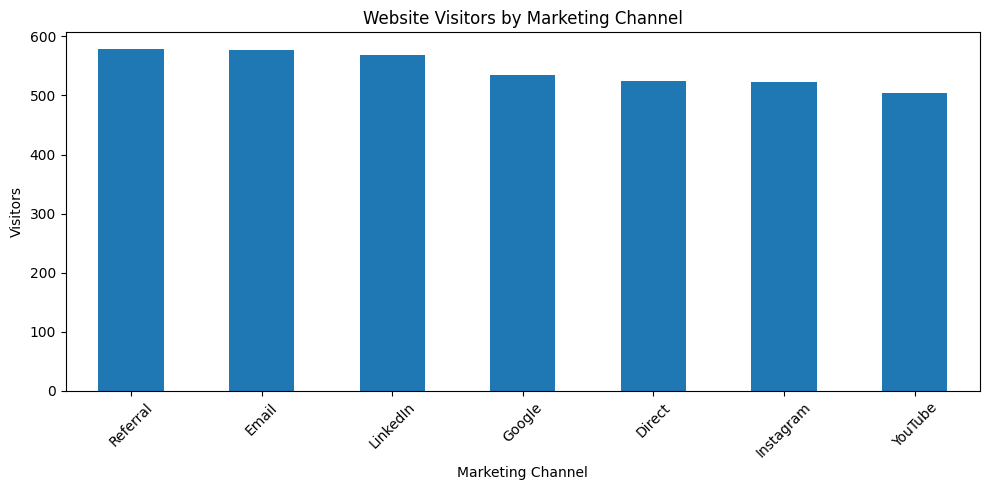

In [14]:
plt.figure(figsize=(10,5))

channel_visitors.plot(kind="bar")

plt.title("Website Visitors by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Visitors")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
city_visitors = (
    df.groupby("City")["Website_Visit"]
    .sum()
    .sort_values(ascending=False)
)

city_visitors

,Website_Visit
City,
Bengaluru,401
Guntur,391
Kochi,388
Chennai,386
Mumbai,386
Pune,386
Coimbatore,375
Hyderabad,373
Vijayawada,371


In [16]:
marketing_analysis = df.groupby(
    "Marketing_Channel"
).agg(
    Visitors=("Website_Visit", "sum"),
    Page_Views=("Page_Views", "sum"),
    Avg_Session=("Session_Duration", "mean"),
    Conversions=("Conversion", "sum"),
    Revenue=("Revenue", "sum")
)

marketing_analysis["Conversion_Rate"] = (
    marketing_analysis["Conversions"]
    / marketing_analysis["Visitors"].replace(0, np.nan)
) * 100

marketing_analysis = marketing_analysis.sort_values(
    "Conversions",
    ascending=False
)

marketing_analysis

,Visitors,Page_Views,Avg_Session,Conversions,Revenue,Conversion_Rate
Marketing_Channel,,,,,,
LinkedIn,568,4381,6.021965,152,7316819.29,26.760563
Email,577,4433,6.027441,130,7494737.36,22.530329
Referral,578,4490,5.936501,122,7614234.17,21.107266
Instagram,522,4343,6.241396,119,6966593.41,22.796935
YouTube,505,3972,6.103081,113,6738934.75,22.376238
Google,534,4206,5.753928,111,6734784.78,20.786517
Direct,525,4106,6.125660,101,6889381.11,19.238095


In [17]:
internship = df[
    df["Inquiry_Type"] == "Internship"
]

internship_summary = internship.groupby(
    "Application_Status"
).size()

internship_summary

,0
Application_Status,
Applied,271
Rejected,262
Selected,251
Shortlisted,264


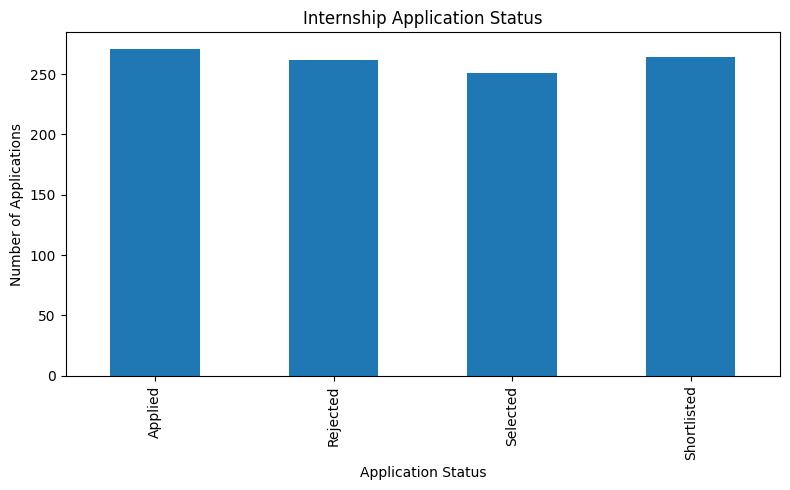

In [18]:
plt.figure(figsize=(8,5))

internship_summary.plot(kind="bar")

plt.title("Internship Application Status")
plt.xlabel("Application Status")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.show()

In [19]:
applications = internship["Application_Submitted"].sum()

selected = (
    internship["Application_Status"] == "Selected"
).sum()

application_selection_rate = (
    selected / applications * 100
    if applications > 0 else 0
)

print(
    f"Internship selection rate: "
    f"{application_selection_rate:.2f}%"
)

Internship selection rate: 67.29%


In [20]:
training_analysis = df.groupby(
    "Training_Program"
).agg(
    Enrollments=("Training_Enrollment", "sum"),
    Completions=("Training_Completion", "sum"),
    Avg_Score=("Training_Score", "mean"),
    Avg_Satisfaction=("Satisfaction_Score", "mean")
)

training_analysis["Completion_Rate"] = (
    training_analysis["Completions"]
    / training_analysis["Enrollments"].replace(0, np.nan)
) * 100

training_analysis

,Enrollments,Completions,Avg_Score,Avg_Satisfaction,Completion_Rate
Training_Program,,,,,
Artificial Intelligence,393,680,69.500000,3.006061,173.027990
Data Analytics,418,681,70.385312,2.978873,162.918660
Machine Learning,433,703,69.506268,2.967213,162.355658
Python for Data Science,376,647,70.840580,3.026915,172.074468
Web Development,396,718,69.561698,2.994077,181.313131


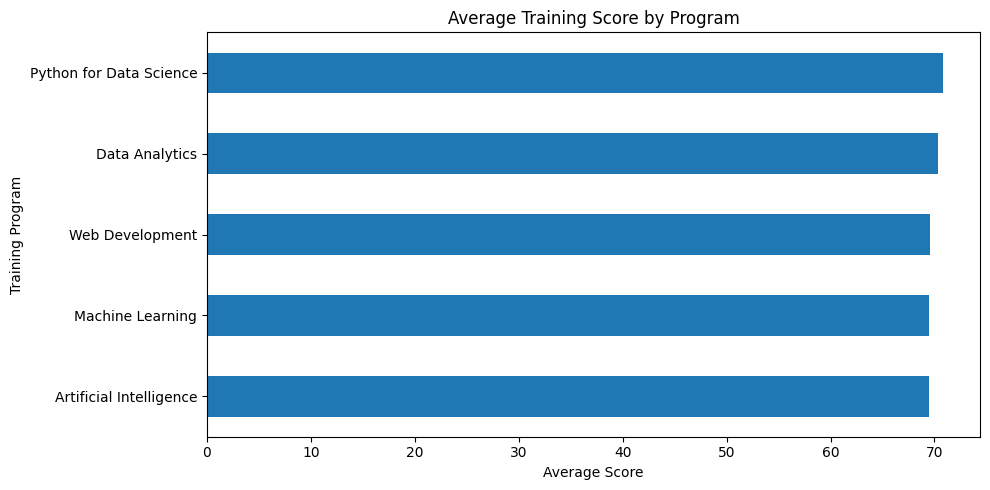

In [21]:
plt.figure(figsize=(10,5))

training_analysis["Avg_Score"].sort_values().plot(
    kind="barh"
)

plt.title("Average Training Score by Program")
plt.xlabel("Average Score")
plt.ylabel("Training Program")

plt.tight_layout()
plt.show()

In [22]:
service_demand = (
    df.groupby("Service")["Service_Request"]
    .sum()
    .sort_values(ascending=False)
)

service_demand

,Service_Request
Service,
Software Development,238
Digital Marketing,238
Technical Support,231
Cloud Services,221
Data Analytics Training,221
AI Internship,217
Web Development,216
Data Science Internship,210
Website Development,208


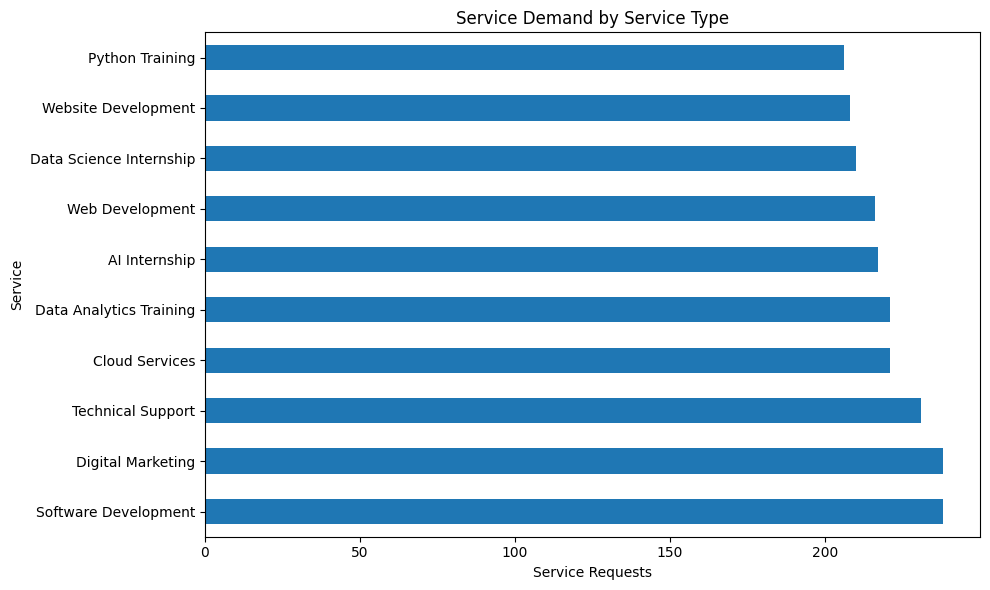

In [23]:
plt.figure(figsize=(10,6))

service_demand.plot(kind="barh")

plt.title("Service Demand by Service Type")
plt.xlabel("Service Requests")
plt.ylabel("Service")

plt.tight_layout()
plt.show()

In [24]:
it_services = df[
    df["Inquiry_Type"] == "IT Service"
]

it_services.groupby(
    "Service"
).agg(
    Requests=("Service_Request", "sum"),
    Avg_Response_Time=("Response_Time_Hours", "mean"),
    Avg_Satisfaction=("Satisfaction_Score", "mean")
)

,Requests,Avg_Response_Time,Avg_Satisfaction
Service,,,
AI Internship,42,6.422660,3.308511
Cloud Services,38,5.038421,3.078947
Data Analytics Training,46,5.723398,2.864078
Data Science Internship,41,5.814752,2.891089
Digital Marketing,59,5.802804,3.074766
Python Training,39,5.305465,3.023256
Software Development,51,5.896577,3.018018
Technical Support,51,5.685776,2.810345
Web Development,48,5.599915,3.101695


In [25]:
digital_services = df[
    df["Inquiry_Type"] == "Digital Service"
]

digital_services.groupby(
    "Service"
).agg(
    Requests=("Service_Request", "sum"),
    Avg_Response_Time=("Response_Time_Hours", "mean"),
    Avg_Satisfaction=("Satisfaction_Score", "mean")
)

,Requests,Avg_Response_Time,Avg_Satisfaction
Service,,,
AI Internship,44,6.454362,3.031915
Cloud Services,35,6.148529,2.931373
Data Analytics Training,50,6.787353,2.803922
Data Science Internship,41,5.791375,3.100000
Digital Marketing,51,6.167921,2.891089
Python Training,42,6.175743,2.900990
Software Development,48,5.197263,2.863158
Technical Support,41,5.793483,2.797753
Web Development,33,5.682118,3.258824


In [26]:
request_analysis = df.groupby(
    "Request_Priority"
).agg(
    Requests=("Service_Request", "sum"),
    Avg_Response_Time=("Response_Time_Hours", "mean"),
    Avg_Satisfaction=("Satisfaction_Score", "mean")
)

request_analysis

,Requests,Avg_Response_Time,Avg_Satisfaction
Request_Priority,,,
Critical,129,6.152604,2.939623
High,554,6.245789,2.937398
Low,538,5.981839,3.030912
Medium,985,5.781583,3.010855


In [27]:
status_analysis = (
    df.groupby("Inquiry_Status")
    .size()
    .sort_values(ascending=False)
)

status_analysis

,0
Inquiry_Status,
Closed,1027
Resolved,1027
Converted,1020
In Progress,975
New,951


In [28]:
customer_features = df.groupby(
    "Customer_ID"
).agg(
    Visits=("Website_Visit", "sum"),
    Page_Views=("Page_Views", "sum"),
    Session_Duration=("Session_Duration", "mean"),
    Revenue=("Revenue", "sum"),
    Satisfaction=("Satisfaction_Score", "mean"),
    Service_Requests=("Service_Request", "sum")
)

customer_features.head()

,Visits,Page_Views,Session_Duration,Revenue,Satisfaction,Service_Requests
Customer_ID,,,,,,
CUST00001,1,5,8.78,5233.12,4.0,0
CUST00002,1,7,4.31,4447.19,2.0,0
CUST00003,1,3,3.71,27831.17,5.0,0
CUST00004,1,5,2.25,7150.75,4.0,0
CUST00005,1,6,11.17,6630.04,2.0,1


In [29]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    customer_features
)

In [30]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_features["Segment"] = kmeans.fit_predict(
    X_scaled
)

In [31]:
segment_summary = customer_features.groupby(
    "Segment"
).mean()

segment_summary

,Visits,Page_Views,Session_Duration,Revenue,Satisfaction,Service_Requests
Segment,,,,,,
0,0.92911,5.971342,6.772006,18571.011961,3.230769,0.251885
1,1.00000,6.027523,5.976370,8837.912562,2.939056,1.000000
2,1.00000,6.009598,5.844163,7920.339028,2.958608,0.000000
3,0.00000,5.905594,5.938068,9399.514170,2.982517,0.448427


In [32]:
features = [
    "Age",
    "Page_Views",
    "Session_Duration",
    "Response_Time_Hours",
    "Satisfaction_Score",
    "Website_Visit",
    "Conversion"
]

X = df[features]
y = df["Revenue"]

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [34]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [35]:
y_pred = model.predict(X_test)

In [36]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 4072.6613137
RMSE: 5233.53097023842
R²  : -0.08587022464337246


In [37]:
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(
    ascending=False
)

importance

,0
Response_Time_Hours,0.295314
Session_Duration,0.286887
Age,0.177610
Page_Views,0.105888
Satisfaction_Score,0.081586
Website_Visit,0.027377
Conversion,0.025339


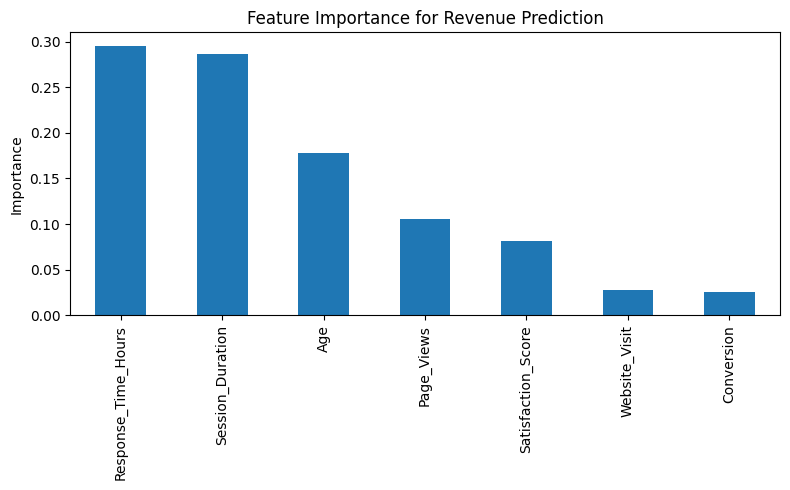

In [38]:
plt.figure(figsize=(8,5))

importance.plot(kind="bar")

plt.title("Feature Importance for Revenue Prediction")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

In [39]:
total_visitors = df["Website_Visit"].sum()

total_inquiries = len(df)

total_service_requests = df["Service_Request"].sum()

total_revenue = df["Revenue"].sum()

total_conversions = df["Conversion"].sum()

conversion_rate = (
    total_conversions / total_visitors * 100
    if total_visitors > 0 else 0
)

avg_satisfaction = df[
    "Satisfaction_Score"
].mean()

avg_response_time = df[
    "Response_Time_Hours"
].mean()

print("Total Visitors:", total_visitors)
print("Total Inquiries:", total_inquiries)
print("Service Requests:", total_service_requests)
print("Revenue:", round(total_revenue, 2))
print("Conversions:", total_conversions)
print("Conversion Rate:", round(conversion_rate, 2), "%")
print("Average Satisfaction:", round(avg_satisfaction, 2))
print("Average Response Time:", round(avg_response_time, 2))

Total Visitors: 3809
Total Inquiries: 5000
Service Requests: 2206
Revenue: 49755484.87
Conversions: 848
Conversion Rate: 22.26 %
Average Satisfaction: 2.99
Average Response Time: 5.97
